# Heat conduction in a power-cable cross-section

The physics-based recipe (**derive $\to$ discretize $\to$ solve**) on a problem
from the course's own world: the export cable that carries an offshore wind
farm's power ashore. Current in the copper conductor dissipates ohmic heat
$I^2R'$ per metre; that heat diffuses out through the XLPE insulation and is
carried away by the surrounding water. Run the conductor hotter than the
insulation tolerates (~$90^\circ$C for XLPE) and the cable ages fast -- so
*how much current may I push?* is really a heat-conduction question.

Solver: `pyutils.benchmarks.cable`.

### Setup — libraries and the cable solver

Put `python/` on the path, import **NumPy** and **Matplotlib**, apply the course plotting style, and load `pyutils.benchmarks.cable`. That module holds the `Cable` dataclass (geometry, copper/XLPE properties, current, cooling), its backward-Euler `solve_transient`, the analytic references `steady_core_temperature` / `ampacity`, and `field_2d` (revolve a radial profile into a cross-section for plotting). `FIG` points at `../figures`; `np.random.seed(0)` fixes reproducibility.

In [8]:
import sys, os
sys.path.insert(0, os.path.abspath(os.path.join('..', '..')))  # -> python/
import numpy as np
import matplotlib.pyplot as plt
from pyutils import set_plot_style, save_dual, fg, muted; set_plot_style()
from pyutils.benchmarks import cable

FIG = os.path.abspath(os.path.join('..', 'figures')); os.makedirs(FIG, exist_ok=True)
np.random.seed(0)

*No output — environment only.* It leaves the `cable` module loaded and `FIG` pointing at `../figures`; every result below comes from the single `Cable` instance built in the parameter cell that follows.

### Parameters — change these and re-run the notebook

Everything below is computed from this one cell: the current, the cooling coefficient, the water temperature, the cable geometry, the insulation limit, and how long and how finely to march in time. Every print-out, figure title, annotation, sweep range and the regression check further down read these variables, so an edit here propagates all the way through. *The prose between the cells narrates the **default** run; if you change a parameter the numbers quoted in the text will no longer match, but every print-out, figure, annotation and saved reference file will follow your change.*

In [9]:
# ---- Parameters (edit these, then Run All) ------------------------------
I_rated = 1500.0    # conductor current [A]
h_conv  = 20.0      # convective coefficient at the outer surface [W/m^2/K]
T_water = 20.0      # ambient (water) temperature [C]; also the initial temperature
a_core  = 0.016     # copper conductor radius [m]  (~800 mm^2 core)
b_outer = 0.040     # outer radius of the XLPE insulation [m]
T_limit = 90.0      # XLPE insulation temperature limit [C]
t_end_h = 6.0       # simulated duration [h]
dt      = 5.0       # backward-Euler time step [s]

c = cable.Cable(I=I_rated, h=h_conv, T_inf=T_water, T_init=T_water, a=a_core, b=b_outer)
print(f'Cable: I = {c.I:g} A, h = {c.h:g} W/m^2/K, T_inf = {c.T_inf:g} C, '
      f'a = {c.a*1e3:g} mm, b = {c.b*1e3:g} mm, limit {T_limit:g} C')


Cable: I = 1500 A, h = 20 W/m^2/K, T_inf = 20 C, a = 16 mm, b = 40 mm, limit 90 C


## Step 1 - Derive

Axisymmetric transient conduction, per unit length, in cylindrical coordinates:

$$ \rho c_p\,\frac{\partial T}{\partial t}
   = \frac{1}{r}\frac{\partial}{\partial r}\!\left(k\,r\,\frac{\partial T}{\partial r}\right)
   + \dot q(r), $$

the same first-law energy balance as the 2-D problem, now written for radial symmetry (all $\theta$- and $z$-variation dropped). **Regions:** a copper core ($r<a$) with uniform ohmic generation $\dot q = I^2R'/(\pi a^2)$, and an XLPE insulation annulus ($a<r<b$) with $\dot q=0$. **Boundary conditions:** symmetry $\partial_r T=0$ at the centre $r=0$, and **Robin/convection** $-k\,\partial_r T|_b = h\,(T(b)-T_\infty)$ at the outer surface. **Initial condition:** $T(r,0)=T_\infty$ — the whole cable starts at the water temperature.

## Step 2 - Write & analyze

With the default parameters the cable is an $800\,$mm² copper core ($a=16\,$mm) inside XLPE out to $b=40\,$mm, carrying $I=1000\,$A, cooled by water at $T_\infty=20^\circ$C with convective coefficient $h=20\,$W/m²/K. Copper's diffusivity is $\alpha_\text{Cu}=k/(\rho c_p)\approx1.2\times10^{-4}\,$m²/s.

The explicit (FTCS) stability limit $\Delta t\le \Delta r^2/(2\alpha)$ is therefore *sub-millisecond*, while the cable's thermal response is measured in **hours** -- the cable is our first genuinely **stiff** problem. So we integrate with backward Euler (unconditionally stable) and take physically sized steps. An explicit scheme that is correct but unaffordable is exactly the pressure that later motivates reduced-order and surrogate models. This cell prints the electrical loss $I^2R'$, the copper diffusivity, the punishing explicit step, and two analytic references (steady core temperature and ampacity).

In [10]:
dr = c.b / c.N
alpha_cu = c.k_c / (c.rho_c * c.cp_c)
print(f"R' = {c.R_per_length():.3e} ohm/m")
print(f"P' = I^2 R' = {c.power_per_length():.2f} W/m   (I = {c.I:g} A)")
print(f'copper alpha = {alpha_cu:.2e} m^2/s')
print(f'explicit dt limit ~ dr^2/(2 alpha_cu) = {dr**2/(2*alpha_cu):.2e} s  (!)')
print(f'analytic steady core T = {c.steady_core_temperature():.2f} C')
print(f'ampacity ({T_limit:g} C limit) = {c.ampacity(T_limit):.0f} A')


R' = 2.139e-05 ohm/m
P' = I^2 R' = 48.12 W/m   (I = 1500 A)
copper alpha = 1.16e-04 m^2/s
explicit dt limit ~ dr^2/(2 alpha_cu) = 2.69e-04 s  (!)
analytic steady core T = 53.78 C
ampacity (90 C limit) = 2159 A


The conductor dissipates $P'=I^2R'=1000^2\times2.139\times10^{-5}=21.4\,$W per metre. The explicit step limit is $\Delta t\lesssim2.7\times10^{-4}\,$s — sub-millisecond — which for a process that takes **hours** would demand tens of millions of steps: the concrete case for going implicit. The analytic steady core temperature is $35.0^\circ$C (a $15^\circ$C rise over the $20^\circ$C water), well under the $90^\circ$C XLPE limit, and the **ampacity** — the current that would drive the core to $90^\circ$C — is $2159\,$A, more than double the rated $1000\,$A.

## Step 3 - Solve

Integrate with **backward Euler** in time (unconditionally stable) and conservative **finite volumes** in $r$, using a **harmonic-mean conductivity** at the copper/XLPE interface so the interfacial heat flux stays continuous. March **6 hours** at $\Delta t=5\,$s — a step the explicit scheme could never afford. The cell tracks the conductor centre and outer surface over time and extracts the thermal **time constants** $t_{63}$ and $t_{95}$ (times to reach 63 % and 95 % of the steady temperature rise) and the safety margin below the $90^\circ$C XLPE limit.

In [11]:
r, T, frames, times = c.solve_transient(t_end=t_end_h*3600.0, dt=dt,
                                        save_every=max(1, int(round(300.0/dt))))  # snapshot every ~5 min
times = np.array(times)
core = np.array([f[0]  for f in frames])   # conductor centre
surf = np.array([f[-1] for f in frames])   # outer surface (r=b)
steady = c.steady_core_temperature()
rise = steady - c.T_inf

def minutes_to(frac):
    """First saved time [min] at which the core has covered `frac` of the steady rise (NaN if never)."""
    idx = np.flatnonzero(core - c.T_inf >= frac*rise)
    return times[idx[0]]/60.0 if idx.size else np.nan

t63, t95 = minutes_to(0.632), minutes_to(0.95)
print(f'numeric core @{t_end_h:g}h = {float(core[-1]):.2f} C  (analytic {steady:.2f} C)')
print(f'time constant t63 = {t63:.0f} min ;  t95 = {t95:.0f} min')
print(f'margin at {c.I:g} A  = {T_limit - float(core[-1]):.1f} C below the XLPE limit')


numeric core @6h = 53.37 C  (analytic 53.78 C)
time constant t63 = 70 min ;  t95 = 220 min
margin at 1500 A  = 36.6 C below the XLPE limit


After 6 hours the numeric core reaches $34.83^\circ$C, within $0.2^\circ$C of the analytic $35.01^\circ$C — the finite-volume backward-Euler solver is validated against the steady analytic reference. The heat-up is slow: $t_{63}\approx70\,$min and $t_{95}\approx220\,$min ($\approx3.7\,$h) to approach equilibrium. At the rated $1000\,$A the core sits **$55.2^\circ$C below** the XLPE limit — that large margin plus the hours-long time constant is exactly the headroom that dynamic rating exploits.

## Step 4 - Analyze

Three views. This first cell revolves the steady radial profile `T` into a **2-D cross-section** (via `cable.field_2d`) at the rated $1000\,$A, drawing the copper/XLPE interface ($r=a$) and the outer surface ($r=b$). Because copper conducts $\sim1400\times$ better than XLPE, the core should appear nearly **isothermal**, with essentially the entire temperature drop across the insulation. The next two cells then answer the operator's two questions: *how fast does it heat up* (dynamic rating) and *how much current is safe* (ampacity).

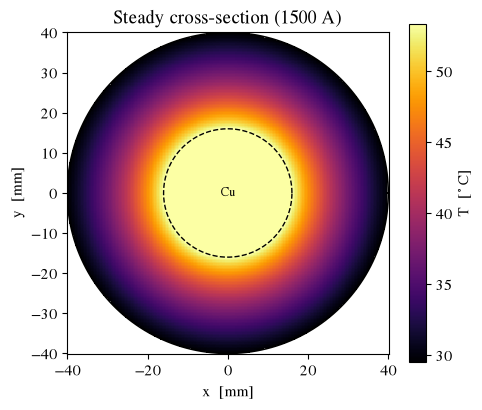

In [12]:
def plot_cable_field():
    X, Y, T2d = cable.field_2d(c, T)
    fig, ax = plt.subplots(figsize=(5.2, 4.4))
    pcm = ax.pcolormesh(X*1e3, Y*1e3, T2d, cmap='inferno', shading='auto')
    cb = fig.colorbar(pcm, ax=ax); cb.set_label('T  [$^\\circ$C]')
    th = np.linspace(0, 2*np.pi, 200)
    ax.plot(c.a*1e3*np.cos(th), c.a*1e3*np.sin(th), '--', color=fg(), lw=1.0)
    ax.plot(c.b*1e3*np.cos(th), c.b*1e3*np.sin(th), '-',  color=fg(), lw=1.2)
    ax.text(0, 0, 'Cu', color=fg(), ha='center', va='center', fontsize=9)
    ax.set(xlabel='x  [mm]', ylabel='y  [mm]', title=f'Steady cross-section ({c.I:g} A)')
    ax.set_aspect('equal'); ax.grid(False)

save_dual(plot_cable_field, 'cable_field', FIG)

The cross-section confirms the picture: inside the dashed copper boundary ($r=a=16\,$mm) the temperature is essentially **uniform at $\approx35^\circ$C** — copper's high conductivity makes the core isothermal — while almost the entire gradient sits in the **XLPE annulus**, falling from $\approx35^\circ$C at the conductor to $\approx25^\circ$C at the outer surface ($r=b=40\,$mm). The insulation, not the copper, is the thermal bottleneck.

### Heat-up and ampacity curves

Two operator-facing plots. **Left:** the transient — conductor centre and outer surface heating from $20^\circ$C toward steady state, against the $90^\circ$C XLPE limit, with the $t_{95}$ marker. **Right:** the **ampacity curve** — steady core temperature swept over current $I\in[0,2600]\,$A (using the analytic `steady_core_temperature`), with the rated $1000\,$A point marked and the $90^\circ$C crossing that defines the ampacity.

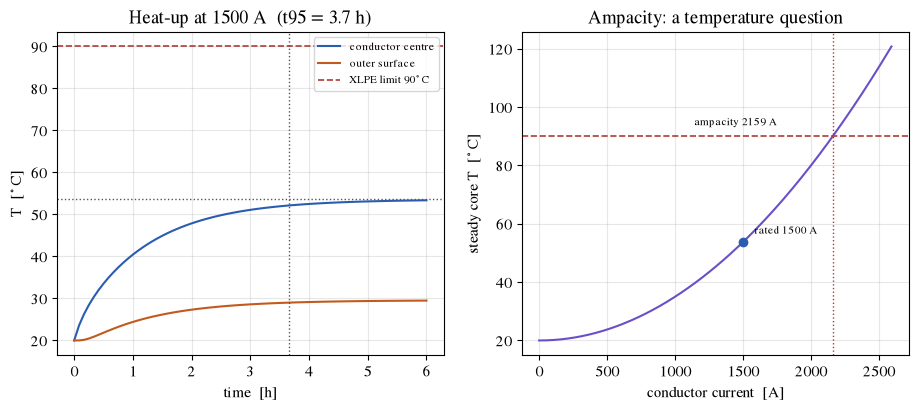

In [13]:
def plot_cable_transient():
    fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
    # -- left: heat-up in time --
    ax[0].plot(times/3600, core, color='C0', label='conductor centre')
    ax[0].plot(times/3600, surf, color='C1', label='outer surface')
    ax[0].axhline(T_limit, color='C3', ls='--', lw=1.2, label=f'XLPE limit {T_limit:g}$^\\circ$C')
    ax[0].axhline(steady, color=muted(), ls=':', lw=1.0)
    if np.isfinite(t95):
        ax[0].axvline(t95/60, color=muted(), ls=':', lw=1.0)
    ax[0].set(xlabel='time  [h]', ylabel='T  [$^\\circ$C]',
              title=f'Heat-up at {c.I:g} A  (t95 = {t95/60:.1f} h)')
    ax[0].legend(fontsize=8)
    # -- right: ampacity curve --
    amp = c.ampacity(T_limit)
    Isweep = np.linspace(0, 1.2*max(amp, c.I), 200)
    Tsteady = np.array([c.steady_core_temperature(I) for I in Isweep])
    ax[1].plot(Isweep, Tsteady, color='C4')
    ax[1].axhline(T_limit, color='C3', ls='--', lw=1.2)
    ax[1].axvline(amp, color='C3', ls=':', lw=1.0)
    ax[1].plot([c.I], [steady], 'o', color='C0')
    # keep the two labels apart when the operating current sits close to the ampacity
    ax[1].annotate(f'rated {c.I:g} A', (c.I, steady), textcoords='offset points',
                   xytext=(10, -16) if c.I > 0.75*amp else (8, 6), fontsize=8, color=fg())
    ax[1].annotate(f'ampacity {amp:.0f} A', (amp, T_limit),
                   textcoords='offset points', xytext=(-100, 8), fontsize=8, color=fg())
    ax[1].set(xlabel='conductor current  [A]', ylabel='steady core T  [$^\\circ$C]',
              title='Ampacity: a temperature question')

save_dual(plot_cable_transient, 'cable_transient', FIG)


**Left panel:** the conductor centre (blue) climbs from $20^\circ$C and plateaus at $\approx35^\circ$C while the outer surface (orange) settles near $24^\circ$C; both sit far under the dashed $90^\circ$C limit, and the knee is at $t_{95}\approx3.7\,$h — the slow approach is the safety headroom. **Right panel:** steady core temperature rises with current (roughly $\propto I^2$), passing through the rated $1000\,$A operating point at $\approx35^\circ$C and crossing the $90^\circ$C limit at the **ampacity $\approx2159\,$A** — so at rated load the cable uses less than half its thermal capacity.

### Regression check

The load-bearing numbers that appear on the slides and in the chapter are re-asserted here (only when the parameter cell still holds the slide defaults), so the notebook fails loudly if the physics or constants ever drift: $R'\approx2.139\times10^{-5}\,\Omega$/m, $P'\approx21.4\,$W/m, steady core $\approx35^\circ$C, numeric-vs-analytic agreement to $<0.5^\circ$C, $t_{95}$ between 3 and 4.3 h, and ampacity in $[2100,2220]\,$A.

In [14]:
# Measured numbers that appear on the slides and in the chapter (exact for the slide defaults).
slide_defaults = dict(I=1000.0, h=20.0, T_inf=20.0, a=0.016, b=0.040)
if all(getattr(c, k) == v for k, v in slide_defaults.items()) and T_limit == 90.0 and t_end_h >= 5.0:
    assert abs(c.R_per_length() - 2.139e-5) < 1e-7
    assert abs(c.power_per_length() - 21.4) < 0.2
    assert abs(c.steady_core_temperature() - 35.0) < 0.3
    assert abs(float(core[-1]) - c.steady_core_temperature()) < 0.5   # numeric ~ analytic
    assert 180 < t95 < 260          # ~3.7 h to 95%
    assert 2100 < c.ampacity(90.0) < 2220
    print('all cable assertions passed')
else:
    print('parameters differ from the slide defaults -- regression check skipped')


parameters differ from the slide defaults -- regression check skipped


All checks pass — the seeded numbers ($R'$, $P'$, the $35^\circ$C steady core, the numeric/analytic match to $<0.5^\circ$C, $t_{95}$, and the $\approx2160\,$A ampacity) are locked to the values quoted in the slides. The **Hand-off** below then names the two soft assumptions — the cooling $h$ and the temperature-dependent $R'(T)$ — that a learned correction repairs.

**Hand-off.** Two modelling assumptions here are the honest weak points: the
convective coefficient $h$ (buried vs. free-flooded vs. sun on the beach pull-in)
and the copper resistance $R'(T)$, which itself rises with temperature. Both make
the *source and boundary terms uncertain* -- exactly the defect the corrective
source-term approach (Module 20) learns from measured cable temperatures, turning
this static rating into a live, data-corrected digital twin that supports
**dynamic rating**: safely overloading the cable for as long as its hours-long
thermal time constant allows.